In [17]:
import xarray as xr
import cartopy.crs as ccrs
import numpy as np
from pystormtracker.preprocessing import SHTFilter
import sys
import os
from pathlib import Path
import pystormtracker as pst
module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *
from plotting import *


In [18]:
setup_plotting();

In [19]:
DATA_PATH ='/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5_pressure_levels/19981999_DJF_globe.nc'
data_set = xr.open_dataset(DATA_PATH)
data_set

<xarray.Dataset> Size: 3GB
Dimensions:         (valid_time: 720, pressure_level: 1, latitude: 721,
                     longitude: 1440)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
    number          int64 8B ...
Data variables:
    vo              (valid_time, pressure_level, latitude, longitude) float32 3GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-16T08:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [20]:
DATE ="1998-12-24T00:00:00"
vo = data_set['vo'].sel(pressure_level=850).sel(valid_time = DATE)*1e5
vo


<xarray.DataArray 'vo' (latitude: 721, longitude: 1440)> Size: 4MB
array([[-3.1546223, -3.1546223, -3.1546223, ..., -3.1546223, -3.1546223,
        -3.1546223],
       [-3.9056408, -3.9056408, -3.9056408, ..., -3.9056408, -3.9056408,
        -3.9056408],
       [-4.328834 , -4.3228736, -4.3109527, ..., -4.352676 , -4.3467155,
        -4.340755 ],
       ...,
       [-6.063329 , -6.0573688, -6.0514083, ..., -6.087171 , -6.0812106,
        -6.07525  ],
       [-5.0142875, -5.0023665, -4.996406 , ..., -5.04409  , -5.032169 ,
        -5.0262084],
       [-4.0546527, -4.0546527, -4.0546527, ..., -4.0546527, -4.0546527,
        -4.0546527]], shape=(721, 1440), dtype=float32)
Coordinates:
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
    number          int64 8B ...
    valid_time      datetime64[ns] 8B 1998-12-24
    pressure_level  float64 8B 850.0
    expver          <U4 16B ...
Attributes: (12/31)
    GRIB_paramId:                             138
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           vo
    GRIB_totalNumber:                         0
    GRIB_units:                               s**-1
    long_name:                                Vorticity (relative)
    units:                                    s**-1
    standard_name:                            atmosphere_relative_vorticity

In [21]:
track_path ='/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6.trackjson'
tracks = pst.load_tracks(track_path)
tracks, summary, points = pro.postprocess_tracks(tracks,**POSTPROCESS_CONFIG)


In [22]:
kept = summary[summary['keep'] == True]
kept_points = points[points['track_id'].isin(kept['track_id'])]

points_at_time = kept_points[kept_points['time'] == DATE]
points_at_time


removed_points = points[points['track_id'].isin(summary[summary['keep'] == False]['track_id'])]
removed_points_at_time = removed_points[removed_points['time'] == DATE]
removed_points_at_time

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo,step_km,in_region,at_edge
1753,243,1998-12-24,-0.25,93.50,0.0,0.0,0.0,0.0,0.0,0.000031,0.000031,27.798467,False,True
3628,555,1998-12-24,10.00,-76.75,0.0,0.0,0.0,0.0,0.0,0.000029,0.000029,61.981285,False,True
5474,815,1998-12-24,57.75,-85.00,0.0,0.0,0.0,0.0,0.0,0.000035,0.000035,183.725692,False,False
6300,982,1998-12-24,-78.75,-103.75,0.0,0.0,0.0,0.0,0.0,0.000037,0.000037,32.299795,False,True
6392,991,1998-12-24,-42.75,32.25,0.0,0.0,0.0,0.0,0.0,0.000045,0.000045,347.462042,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13096,2109,1998-12-24,-39.75,-82.25,0.0,0.0,0.0,0.0,0.0,0.000037,0.000037,35.041495,False,True
13127,2119,1998-12-24,1.50,82.50,0.0,0.0,0.0,0.0,0.0,0.000019,0.000019,117.908038,False,True
13199,2128,1998-12-24,-39.00,-88.75,0.0,0.0,0.0,0.0,0.0,0.000036,0.000036,455.263310,False,True
13217,2130,1998-12-24,-42.50,-33.00,0.0,0.0,0.0,0.0,0.0,0.000021,0.000021,0.000000,False,True


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


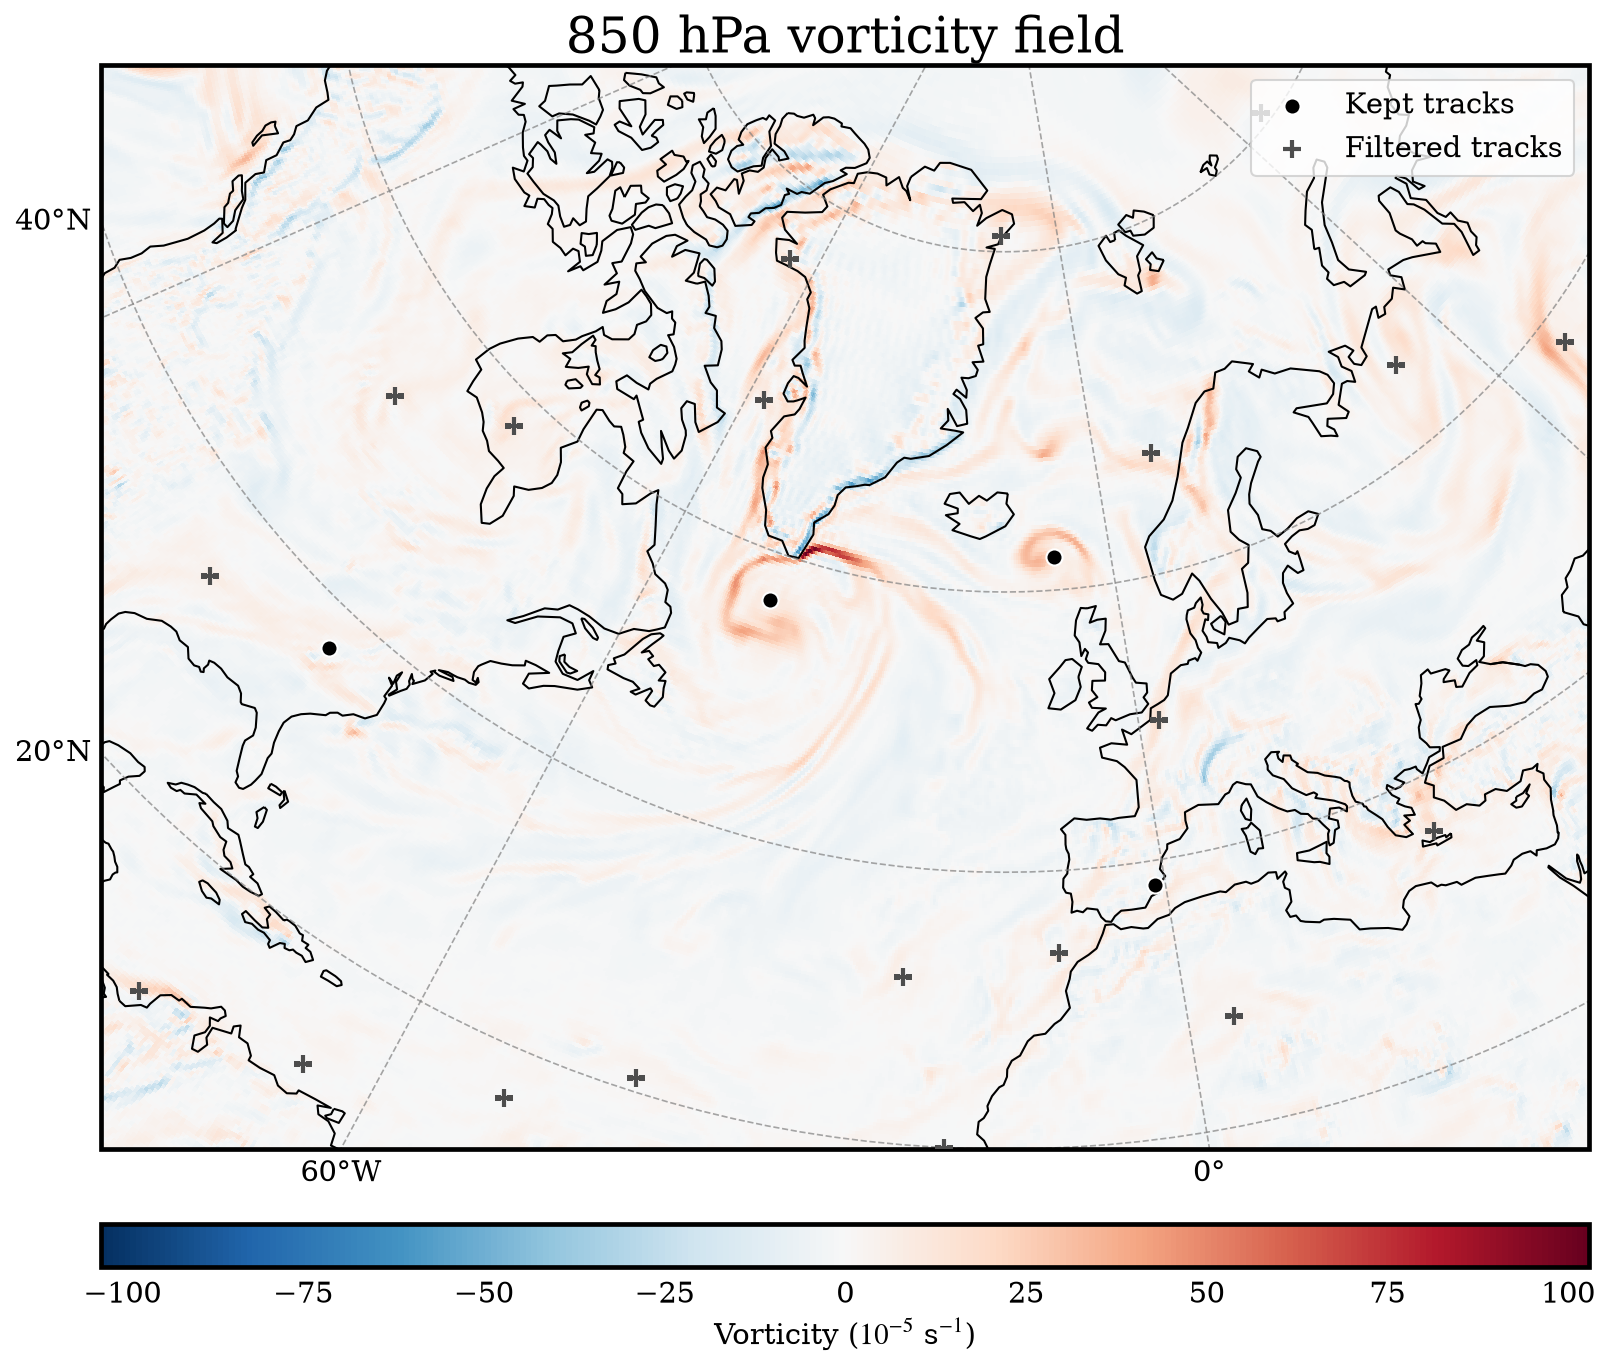

In [23]:
           # read the frame into memory once, in 10^-5 s^-1
vmax = float(abs(vo).max())                 # symmetric limits so white = 0
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = geo_map(projection=proj, extent=[DOMAIN[0], DOMAIN[1], DOMAIN[2], 85],
                  frame="box", width=12)         # zoom to the tracking domain
im = vo.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
             vmin=-vmax, vmax=vmax, add_colorbar=False)
ax.set_title("850 hPa vorticity field")

add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", pad=0.5, labelsize=14)
ax.scatter(points_at_time['lon'], points_at_time['lat'], s=60,
           facecolor="k", edgecolor="white", linewidth=1,
           label="Kept tracks", transform=ccrs.PlateCarree(), zorder=5)
ax.scatter(removed_points_at_time['lon'], removed_points_at_time['lat'], s=80,
           color="0.3", marker="+", linewidth=2,
           label="Filtered tracks", transform=ccrs.PlateCarree(), zorder=5)
ax.legend(loc="upper right", fontsize=14)


In [24]:
vo = data_set['vo'].sel(pressure_level=850).sel(valid_time = DATE)
vo_filtered = SHTFilter( lmin=6, lmax=42, taper_val=0.1).filter(vo)*1e5


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.1

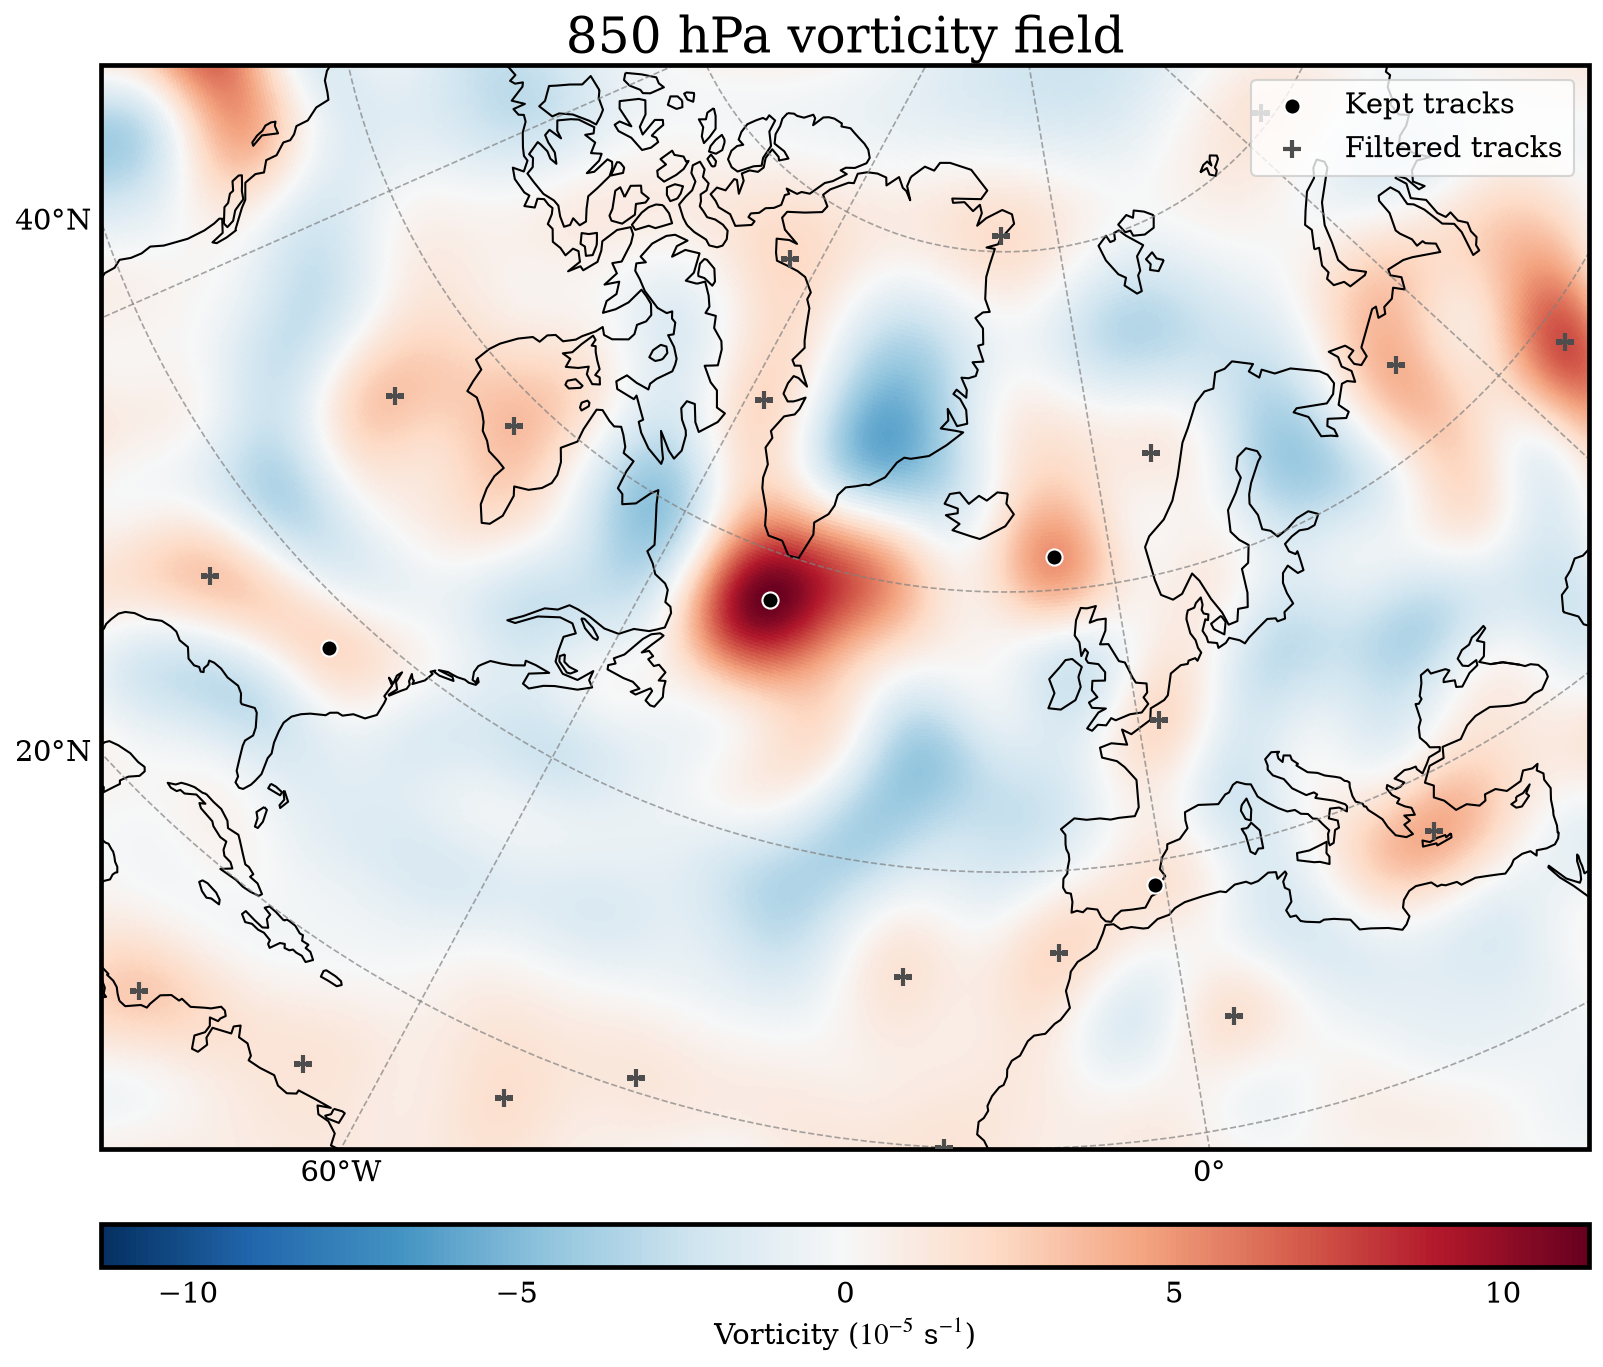

In [25]:
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)


pc = ccrs.PlateCarree()

vmax = float(abs(vo_filtered).max())
fig, ax = geo_map(projection=proj, extent=[DOMAIN[0], DOMAIN[1], DOMAIN[2], 85],
                  frame="box", width=12)
im = vo_filtered.plot(ax=ax, transform=pc, cmap="RdBu_r",
                      vmin=-vmax, vmax=vmax, add_colorbar=False)

ax.scatter(points_at_time['lon'], points_at_time['lat'], s=60,
           facecolor="k", edgecolor="white", linewidth=1,
           label="Kept tracks", transform=pc, zorder=5)
ax.scatter(removed_points_at_time['lon'], removed_points_at_time['lat'], s=80,
           color="0.3", marker="+", linewidth=2,
           label="Filtered tracks", transform=pc, zorder=5)

ax.set_title("850 hPa vorticity field")
add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", pad=0.5, labelsize=14)
ax.legend(loc="upper right", fontsize=14)

plt.savefig("/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/experiments/example_cases/vorticity_field.png", dpi=300, bbox_inches="tight")